In [2]:
#import libs
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import importlib

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP
import BlockTools as BT




In [ ]:
#import reanalysis data. we use data from 2003
fn = "/home/guest/work/michele/data/ERA5/Z500/"+\
         "ERA5_Z500_day_djfm_r144x73_500hPa_northem_2012.nc"
fn_out = "/home/guest/work/michele/data/ERA5/processed/"+\
         "ERA5_pIB_tracked_daily_jja_northem_2012.nc"

In [3]:
#try contour tracking
ds=xr.load_dataset(fn)
ds = ds.mean(dim="plev")
ds = BT.DAV(ds,data_return=True,freq_also=True,mer_gradient_filter=False)
BT.ContourTracking2D(ds,fn_out,pers=4,min_area=500000,overlap=0.7)
print("Data created")

  0%|          | 0/121 [00:00<?, ?it/s]

__Starting a DAV process__
input: zg500 , freq_also = True, mer_gradient_filter = False
__Starting a Tracking process__
input: DAV, pers = 4


100%|██████████| 19/19 [00:00<00:00, 3219.35it/s]

exited with 0 elements remaining
19 blocking events where found
number of labels: 19
saving netcdf in: /home/guest/work/michele/data/ERA5/processed/ERA5_pIB_tracked_daily_jja_northem_2012.nc
Data created


100%|██████████| 4/4 [00:00<00:00, 8101.02it/s]


Starting job
34 49


/work/users/guest/michele/environments/BT_env/lib/python3.8/site-packages/cartopy/mpl/geoaxes.py:1887: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


0
Plot produced


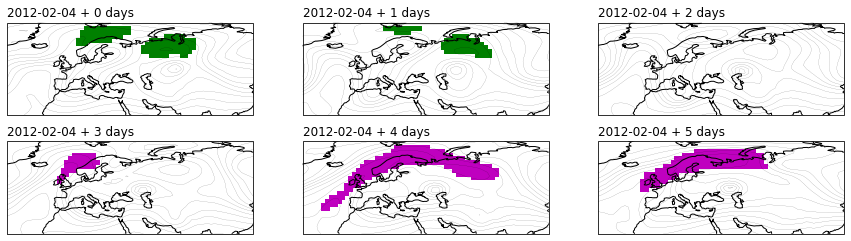

In [4]:
#PLOT
import matplotlib.pyplot as plt
importlib.reload(BP)
fig = plt.figure(figsize=(15,4))


img_out = "/home/guest/work/michele/prog/plots/"+\
        "tracking_validation/"+\
        "CaseStudy_highoverlap.png"
print("Starting job")
ds = xr.load_dataset(fn_out)
#print(ds["time"])
print(BP.PlotTracking(ds=ds,output = img_out,\
      starting_day="2012-02-04T09:00:00.000000000",extent=[-40,120,20,80]))
print("Plot produced")